# Microduck built in MuJoCo from its STL meshes

The same robot as `walk.ipynb`, but assembled in Python with `mujoco.MjSpec` instead of loaded from an MJCF file.
Inputs: the CAD meshes `model/assets/*.stl`, the CAD numbers in section 1 and the policy `velstand.onnx`.
The robot XML is read only once, in section 4, to check that the build is the same model.

| Section | Notebook | Modelica `MicroDuck` library |
|---|---|---|
| 1 | CAD data tables | parameters of `Components.Robot` |
| 2 | `add_link`, `add_geom` | `Components.Link` |
| 3 | `build()`: tree, meshes, scene | `Components.Robot`: instances and `connect` |
| 4 | Check against the reference MJCF | forward-kinematics check |
| 5 | BAM servo, robot standing | `Components.PositionServo`, `Examples.Standing` |
| 6 | Walking policy at 0.3 m/s | `Components.WalkingPolicy`, `Examples.WalkingTest` |

In [1]:
from pathlib import Path

import imageio
import matplotlib.pyplot as plt
import mujoco
import numpy as np
import onnxruntime as ort
from IPython.display import Video

HERE = Path.cwd()
MESHES = HERE / "model" / "assets"
ONNX = str(HERE / "velstand.onnx")
VIDEO = HERE / "build_duck.mp4"
REFERENCE = str(HERE / "model" / "scene_backlash.xml")  # section 4 check only
WIDTH, HEIGHT = 960, 540
print("mujoco", mujoco.__version__)

mujoco 3.15.0


## 1. CAD data

Exported from the Pollen Robotics Onshape assembly by `onshape-to-robot` (`microduck_rl`, backlash variant) and copied
here once. SI units, quaternions `(w, x, y, z)`. Each link body sits in its parent's frame at `pos`, `quat`; its hinge
turns about the local `axis`. `com` and `inertia` are about the centre of mass in the body frame.

In [2]:
TRUNK = {"pos": (0, 0, 0.12), "mass": 0.199224, "com": (-0.0226332, -2.70828e-05, 0.00280064), "inertia": (0.000123975, 0.000145931, 0.000115351, 7.1651e-08, -2.06915e-05, 1.32429e-07)}

LINKS = [  # name, parent, pos, quat, mass, com, inertia (xx yy zz xy xz yz), joint, axis, range
    ('yaw2roll', 'trunk_base', (0.006, 0.0175, -0.005), (0, -0.707107, -0.707107, 0), 0.0230406, (-8.8e-11, 0.00099414, 0.0168917), (4.1964e-06, 3.41752e-06, 2.3265e-06, 0, 0, -5.0881e-08), 'left_hip_yaw', (0, 0, 1.0), (-0.4363323129985824, 0.5235987755982988)),
    ('hip_l', 'yaw2roll', (0, 0.0165, 0.0125), (0.707107, -0.707107, 0, 0), 0.00618934, (0.014815, 1.6179e-08, -0.00829992), (8.60626e-07, 1.15753e-06, 6.51588e-07, 1e-12, 3.89882e-07, -1e-12), 'left_hip_roll', (0, 0, 1.0), (-0.3839724354386992, 0.38397243543880577)),
    ('upper_leg_left', 'hip_l', (0.025, 0, -0.0185), (0.5, -0.5, 0.5, -0.5), 0.0482067, (0.006766, 0.0228838, 0.0134531), (1.68753e-05, 1.03691e-05, 1.98269e-05, -4.41852e-06, 2.27982e-07, 3.89298e-07), 'left_hip_pitch', (0, 0, 1.0), (-1.570796326794949, 1.5707963267948442)),
    ('leg', 'upper_leg_left', (0.022, 0.0357771, -0.004), (0, 0.707107, 0.707107, 0), 0.0215844, (-1.52e-10, 0.0318937, -0.00953505), (5.25056e-06, 2.15507e-06, 4.33925e-06, -1e-12, 0, 7.65005e-07), 'left_knee', (0, 0, 1.0), (-1.5707963267948983, 1.5707963267948948)),
    ('ankle_left', 'leg', (0, 0.042, -0.026), (0, -1.0, 0, 0), 0.0300246, (-0.00615742, -0.0137483, -0.0156585), (5.91525e-06, 1.11534e-05, 7.74016e-06, -2.05354e-07, 8.218e-08, 5.6722e-08), 'left_ankle', (0, 0, 1.0), (-1.5707963267949063, 1.5707963267948868)),
    ('neck', 'trunk_base', (0.026, 0.0145, 0.0324215), (0, 0, 0.707107, -0.707107), 0.0368414, (0, -0.025, 0.0141665), (1.72925e-05, 3.12694e-06, 1.63707e-05, 0, 0, 0), 'neck_pitch', (0, 0, 1.0), (-1.5707963267948974, 1.0471975511965967)),
    ('neck_pitch', 'neck', (0, -0.05, 0), (0, 1.0, 0, 0), 0.00572, (-6.533e-09, 0.0116641, -0.0145), (1.09186e-06, 9.66855e-07, 5.12111e-07, 0, 0, 0), 'head_pitch', (0, 0, 1.0), (-1.5707963267948966, 1.5707963267948966)),
    ('yaw_roll_motion', 'neck_pitch', (0, 0.0186931, -0.0145), (0, 0, -0.707107, -0.707107), 0.0486, (-0.000166657, -0.00500964, 0.0178065), (6.97903e-06, 8.10293e-06, 9.57884e-06, 3.21657e-07, -3.4797e-08, 3.4295e-07), 'head_yaw', (0, 0, 1.0), (-2.9670597283903613, 2.9670597283903595)),
    ('jaw_soft', 'yaw_roll_motion', (-0.0179, 0, 0.0145), (0.707107, 0, -0.707107, 0), 0.188766, (0.00460523, 0.00120047, -0.0324761), (0.000320811, 0.0002541, 0.000149882, -6.32293e-07, 6.57153e-06, 4.18477e-06), 'head_roll', (0, 0, 1.0), (-0.43633231299858327, 0.4363323129985815)),
    ('bearing_roll', 'trunk_base', (0.006, -0.0175, -0.005), (0, -0.707107, -0.707107, 0), 0.0230406, (-8.8e-11, 0.00099414, 0.0168917), (4.1964e-06, 3.41752e-06, 2.3265e-06, 0, 0, -5.0881e-08), 'right_hip_yaw', (0, 0, 1.0), (-0.523598775598297, 0.43633231299858416)),
    ('hip_l_2', 'bearing_roll', (0, 0.0165, 0.0125), (0, 0, 0.707107, 0.707107), 0.00618934, (0.014815, 1.6212e-08, -0.00829992), (8.60626e-07, 1.15753e-06, 6.51588e-07, 1e-12, 3.89882e-07, -1e-12), 'right_hip_roll', (0, 0, 1.0), (-0.3839724354387507, 0.38397243543875426)),
    ('upper_leg_right', 'hip_l_2', (0.025, 0, -0.0185), (0.5, -0.5, 0.5, -0.5), 0.0482067, (-0.006766, 0.0228838, 0.0134531), (1.68753e-05, 1.03691e-05, 1.98269e-05, 4.41852e-06, -2.27982e-07, 3.89298e-07), 'right_hip_pitch', (0, 0, 1.0), (-1.57079632679494, 1.570796326794853)),
    ('leg_2', 'upper_leg_right', (-0.022, 0.0357771, -0.004), (0, 1.0, 0, 0), 0.0215844, (-0.0318937, -1.52e-10, -0.00953505), (2.15507e-06, 5.25056e-06, 4.33925e-06, 1e-12, -7.65005e-07, 0), 'right_knee', (0, 0, 1.0), (-1.5707963267949339, 1.5707963267948593)),
    ('ankle_right', 'leg_2', (-0.042, 0, -0.026), (0, -0.707107, -0.707107, 0), 0.0300251, (0.00615539, -0.0137482, -0.0156566), (5.91534e-06, 1.11534e-05, 7.74015e-06, 2.04877e-07, -8.2467e-08, 5.7017e-08), 'right_ankle', (0, 0, 1.0), (-1.5707963267949028, 1.5707963267948903)),
]

In [3]:
GEOMS = [  # body, mesh, pos, quat, kind
    ('trunk_base', 'seeed_bearing__configuration__22x16x4', (0.006, 0.0175, -0.005), (1.0, 0, 0, 0), 'visual'),
    ('trunk_base', 'right_shell', (0.004, -0.0005, -0.0175), (0.707107, 0, 0, 0.707107), 'visual'),
    ('trunk_base', 'banana_pcb_locker', (0.0042, 0, -0.0175215), (0.707107, 0, 0, 0.707107), 'visual'),
    ('trunk_base', 'trunk_base', (0.004, 0, -0.0175), (0.707107, 0, 0, 0.707107), 'visual'),
    ('trunk_base', 'xl330', (0.006, 0.0175, 0.0115), (0, -0.707107, 0, -0.707107), 'visual'),
    ('trunk_base', 'power_support', (0.004, 0, -0.0175215), (0.707107, 0, 0, 0.707107), 'visual'),
    ('trunk_base', 'power_support', (0.004, 0, -0.0175215), (0.707107, 0, 0, 0.707107), 'self_collision_only'),
    ('trunk_base', 'np_f970', (-0.0359693, 0, -0.00385049), (0.00617059, 0.70708, -0.70708, -0.00617059), 'visual'),
    ('trunk_base', 'np_f970', (-0.0359693, 0, -0.00385049), (0.00617059, 0.70708, -0.70708, -0.00617059), 'collision'),
    ('trunk_base', 'xl330', (0.006, -0.0175, 0.0115), (0, -0.707107, 0, -0.707107), 'visual'),
    ('trunk_base', 'left_shell', (0.004, 0, -0.0175785), (0.707107, 0, 0, 0.707107), 'visual'),
    ('trunk_base', 'seeed_bearing__configuration__22x16x4', (0.006, -0.0175, -0.005), (1.0, 0, 0, 0), 'visual'),
    ('yaw2roll', 'yaw2roll', (-0.0175, -0.002, 0.0125), (0, 1.0, 0, 0), 'visual'),
    ('yaw2roll', 'xl330', (0, 0, 0.0125), (0, -0.707107, 0.707107, 0), 'visual'),
    ('yaw2roll', 'seeed_bearing__configuration__22x16x4', (0, 0.0165, 0.0125), (0.5, 0.5, 0.5, -0.5), 'visual'),
    ('yaw2roll', 'bearing_roll', (-0.0175, -0.002, 0.0125), (0, -1.0, 0, 0), 'visual'),
    ('hip_l', 'seeed_bearing__configuration__22x16x4', (0.021, 0, -0.0185), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('hip_l', 'hip_l', (-0.0175, 0, -0.0185), (0.707107, -0.707107, 0, 0), 'visual'),
    ('hip_l', 'hip_l', (-0.0175, 0, -0.0185), (0.707107, -0.707107, 0, 0), 'collision'),
    ('upper_leg_left', 'upper_leg_left', (0, 0, -0.0425), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('upper_leg_left', 'xl330', (0.022, 0.0357771, 0.0125), (0, 0.707107, 0, 0.707107), 'visual'),
    ('upper_leg_left', 'upper_leg_rigidity_plate', (0, 0, -0.0425), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('upper_leg_left', 'seeed_bearing__configuration__22x16x4', (0.022, 0.0357771, -0.004), (0, 0, 0, 1.0), 'visual'),
    ('upper_leg_left', 'xl330', (0, 0, 0.0125), (0.5, 0.5, -0.5, 0.5), 'visual'),
    ('leg', 'leg', (-0.022, 0.0357771, 0.0385), (0.5, 0.5, 0.5, -0.5), 'visual'),
    ('leg', 'leg', (-0.022, 0.0357771, 0.0385), (0.5, 0.5, 0.5, -0.5), 'collision'),
    ('leg', 'xl330', (0, 0.042, -0.0115), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('ankle_left', 'sole_left', (-0.022, 0.00622291, -0.0647), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('ankle_left', 'sole_left', (-0.022, 0.00622291, -0.0647), (0.5, -0.5, -0.5, -0.5), 'collision', 'left_foot_collision'),
    ('ankle_left', 'foot_left', (-0.022, 0.00622291, -0.0647), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('ankle_left', 'seeed_bearing__configuration_default', (0, 0, -0.0322), (0, 0, 0, 1.0), 'visual'),
    ('ankle_left', 'ankle_left', (-0.022, 0.00622291, -0.0647), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('neck', 'neck', (0.022, 0.05, 0.028), (0.5, 0.5, 0.5, -0.5), 'visual'),
    ('neck', 'xl330', (0, 0, 0.0145), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('neck', 'xl330', (0, -0.05, 0.0145), (0.5, 0.5, -0.5, 0.5), 'visual'),
    ('neck', 'neck', (0.022, 0.05, 0.003), (0.5, 0.5, 0.5, -0.5), 'visual'),
    ('neck_pitch', 'neck_pitch', (0, 0.0287931, -0.0145), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('neck_pitch', 'seeed_bearing__configuration__22x16x4', (0, 0.0207931, -0.0145), (0.707107, 0.707107, 0, 0), 'visual'),
    ('yaw_roll_motion', 'yaw_roll_motion', (0, 0, 0.01), (0.707107, 0, 0, 0.707107), 'visual'),
    ('yaw_roll_motion', 'xl330', (0, 0, 0.0145), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('yaw_roll_motion', 'seeed_bearing__configuration__22x16x4', (-0.016, 0, 0.0145), (0.707107, 0, -0.707107, 0), 'visual'),
    ('yaw_roll_motion', 'seeed_bearing__configuration__22x16x4', (0.018, 0, 0.0145), (0.707107, 0, -0.707107, 0), 'visual'),
    ('jaw_soft', 'lens', (0.0155, -9.13778e-05, -0.05548), (0.5, -0.5, 0.5, -0.5), 'visual'),
    ('jaw_soft', 'face_part', (-0.0045, -9.13778e-05, -0.0178), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'xl330', (0.003, 0.0255, -0.018), (0.707107, 0, 0, -0.707107), 'visual'),
    ('jaw_soft', 'jaw_soft', (-0.0046, 0, -0.0179996), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'motor_support', (-0.0045, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'top_head_shell', (-0.0045, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'top_head_shell', (-0.0045, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'collision'),
    ('jaw_soft', 'xl330', (0, 0, 0.0145), (0.5, -0.5, -0.5, -0.5), 'visual'),
    ('jaw_soft', 'seeed_bearing__configuration_default', (0.0032, -0.04, -0.018), (0.5, -0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'elec_rpi_robot_hat_pcb', (0.02694, 0.0289936, -0.0519), (0.707107, 0, 0, -0.707107), 'visual'),
    ('jaw_soft', 'soft_mouth_top', (-0.00420071, 1.7776e-08, -0.0180814), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'noenoeil', (-0.0045, -9.13778e-05, -0.0178), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'jaw', (-0.0045, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'jaw', (-0.0045, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'collision'),
    ('jaw_soft', 'bottom_head_shell', (-0.0043, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('jaw_soft', 'bottom_head_shell', (-0.0043, 0, -0.018), (0.5, 0.5, 0.5, 0.5), 'collision'),
    ('jaw_soft', 'm12_lens_holder', (0.0155, -9.13778e-05, -0.05558), (0.5, -0.5, 0.5, -0.5), 'visual'),
    ('jaw_soft', 'pcb__raspberry_pi_zero_2_w', (0.015435, -1.13778e-05, -0.06001), (0.5, -0.5, -0.5, 0.5), 'visual'),
    ('jaw_soft', 'speaker', (0.01, -0.016786, 0.0260226), (0.5, 0.5, 0.5, 0.5), 'visual'),
    ('bearing_roll', 'yaw2roll', (-0.0175, -0.002, 0.0125), (0, 1.0, 0, 0), 'visual'),
    ('bearing_roll', 'xl330', (0, 0, 0.0125), (0, -0.707107, 0.707107, 0), 'visual'),
    ('bearing_roll', 'bearing_roll', (-0.0175, -0.002, 0.0125), (0, 1.0, 0, 0), 'visual'),
    ('bearing_roll', 'seeed_bearing__configuration__22x16x4', (0, 0.0165, 0.0125), (0.5, 0.5, 0.5, -0.5), 'visual'),
    ('hip_l_2', 'hip_l', (-0.0175, 0, -0.0185), (0.707107, -0.707107, 0, 0), 'visual'),
    ('hip_l_2', 'hip_l', (-0.0175, 0, -0.0185), (0.707107, -0.707107, 0, 0), 'collision'),
    ('hip_l_2', 'seeed_bearing__configuration__22x16x4', (0.025, 0, -0.0185), (0.5, 0.5, -0.5, -0.5), 'visual'),
    ('upper_leg_right', 'xl330', (-0.022, 0.0357771, 0.0125), (0.707107, 0, -0.707107, 0), 'visual'),
    ('upper_leg_right', 'seeed_bearing__configuration__22x16x4', (-0.022, 0.0357771, 0), (0, 1.0, 0, 0), 'visual'),
    ('upper_leg_right', 'upper_leg_rigidity_plate', (0, 0, 0.0435), (0.5, -0.5, 0.5, 0.5), 'visual'),
    ('upper_leg_right', 'upper_leg_right', (0, 0, -0.0425), (0.5, -0.5, 0.5, 0.5), 'visual'),
    ('upper_leg_right', 'xl330', (0, 0, 0.0125), (0.5, 0.5, -0.5, 0.5), 'visual'),
    ('leg_2', 'xl330', (-0.042, 0, -0.0115), (0.707107, 0, -0.707107, 0), 'visual'),
    ('leg_2', 'leg', (-0.0357771, -0.022, 0.0385), (0.707107, 0, 0.707107, 0), 'visual'),
    ('leg_2', 'leg', (-0.0357771, -0.022, 0.0385), (0.707107, 0, 0.707107, 0), 'collision'),
    ('ankle_right', 'ankle_right', (0.022, 0.00622291, -0.0647), (0.5, -0.5, 0.5, 0.5), 'visual'),
    ('ankle_right', 'sole_right', (0.022, 0.00622291, -0.0647), (0.5, -0.5, 0.5, 0.5), 'visual'),
    ('ankle_right', 'sole_right', (0.022, 0.00622291, -0.0647), (0.5, -0.5, 0.5, 0.5), 'collision', 'right_foot_collision'),
    ('ankle_right', 'seeed_bearing__configuration_default', (0, 0, -0.0292), (0, -1.0, 0, 0), 'visual'),
    ('ankle_right', 'foot_right', (0.022, 0.00622291, -0.0647), (0.5, -0.5, 0.5, 0.5), 'visual'),
]

In [4]:
COLOURS = {  # rgba per mesh, from the CAD materials
    'seeed_bearing__configuration__22x16x4': (0.811765, 0.858824, 0.898039, 1.0),
    'right_shell': (0.85098, 0.85098, 0.839216, 1.0),
    'banana_pcb_locker': (0.647059, 0.647059, 0.647059, 1.0),
    'trunk_base': (0.129412, 0.152941, 0.129412, 1.0),
    'xl330': (0.286275, 0.286275, 0.286275, 1.0),
    'power_support': (0.67451, 0.639216, 0.603922, 1.0),
    'np_f970': (0.301961, 0.301961, 0.301961, 1.0),
    'left_shell': (0.8, 0.8, 0.8, 1.0),
    'yaw2roll': (0.129412, 0.152941, 0.129412, 1.0),
    'bearing_roll': (0.129412, 0.152941, 0.129412, 1.0),
    'hip_l': (0.67451, 0.639216, 0.603922, 1.0),
    'upper_leg_left': (0.85098, 0.85098, 0.839216, 1.0),
    'upper_leg_rigidity_plate': (0.67451, 0.639216, 0.603922, 1.0),
    'leg': (0.67451, 0.639216, 0.603922, 1.0),
    'sole_left': (0.956863, 0.686275, 0.137255, 1.0),
    'foot_left': (1.0, 0.403922, 0.121569, 1.0),
    'seeed_bearing__configuration_default': (0.811765, 0.858824, 0.898039, 1.0),
    'ankle_left': (1.0, 0.403922, 0.121569, 1.0),
    'neck': (0.67451, 0.639216, 0.603922, 1.0),
    'neck_pitch': (0.34902, 0.376471, 0.4, 1.0),
    'yaw_roll_motion': (0.129412, 0.152941, 0.129412, 1.0),
    'lens': (0.262745, 0.282353, 0.301961, 1.0),
    'face_part': (0.67451, 0.639216, 0.603922, 1.0),
    'jaw_soft': (0.85098, 0.756863, 0.866667, 1.0),
    'motor_support': (0.129412, 0.152941, 0.129412, 1.0),
    'top_head_shell': (0.85098, 0.85098, 0.839216, 1.0),
    'elec_rpi_robot_hat_pcb': (0.313725, 0.486275, 0.411765, 1.0),
    'soft_mouth_top': (0.85098, 0.756863, 0.866667, 1.0),
    'noenoeil': (0.956863, 0.686275, 0.137255, 1.0),
    'jaw': (1.0, 0.403922, 0.121569, 1.0),
    'bottom_head_shell': (1.0, 0.403922, 0.121569, 1.0),
    'm12_lens_holder': (0.262745, 0.282353, 0.301961, 1.0),
    'pcb__raspberry_pi_zero_2_w': (0.498039, 0.498039, 0.498039, 1.0),
    'speaker': (0.294118, 0.290196, 0.290196, 1.0),
    'upper_leg_right': (0.85098, 0.85098, 0.839216, 1.0),
    'ankle_right': (1.0, 0.403922, 0.121569, 1.0),
    'sole_right': (0.956863, 0.686275, 0.137255, 1.0),
    'foot_right': (1.0, 0.403922, 0.121569, 1.0),
}

In [5]:
SITES = [  # name, body, pos, quat
    ('imu', 'trunk_base', (-0.021, 6.64098e-05, -0.0146984), (1.0, 0, 0, 0)),
    ('left_foot', 'ankle_left', (0, -0.0238146, -0.0140852), (0, 0, -0.707107, -0.707107)),
    ('head_camera', 'jaw_soft', (0.0155, -9.13778e-05, -0.0733), (0.707107, 0, 0.707107, 0)),
    ('tof', 'jaw_soft', (0.0135, 0.0224086, -0.0733), (0.707107, 0, 0.707107, 0)),
    ('head_imu', 'jaw_soft', (0.0152323, 0.000111069, -0.05106), (1.0, 0, 0, 0)),
    ('mouth_tip', 'jaw_soft', (-0.00809334, 0, -0.0777383), (0.704015, 0, 0.710185, 0)),
    ('right_foot', 'ankle_right', (0, -0.0238146, -0.0140852), (0.707107, -0.707107, 0, 0)),
]

STAND = {  # home pose of the servos [rad], in the order of the policy
    "left_hip_yaw": 0, "left_hip_roll": -np.radians(5), "left_hip_pitch": -0.457924, "left_knee": -0.00494, "left_ankle": 0.452984,
    "neck_pitch": np.radians(20), "head_pitch": np.radians(20), "head_yaw": 0, "head_roll": 0,
    "right_hip_yaw": 0, "right_hip_roll": np.radians(5), "right_hip_pitch": 0.457924, "right_knee": 0.00494, "right_ankle": -0.452984,
}
JOINTS = list(STAND)
BACKLASH_JOINTS = [f"passive_{j}_backlash" for j in JOINTS]
HEAD = [JOINTS.index(j) for j in ("neck_pitch", "head_pitch", "head_yaw", "head_roll")]

## 2. Building blocks

A link is a body behind two hinges on the same axis: the servo output and, after it, the 1 deg gear play of the
backlash. The servo hinge carries the BAM xl330 rotor inertia and friction; the torque is applied in section 5.
A mesh is either `visual` (no contact), `collision` (contact with the floor) or `self_collision_only`.

In [6]:
# bam/params/xl330/m6.json
ARMATURE = 0.001573222677933975
FRICTION_BASE = 0.011919956825702578
FRICTION_VISCOUS = 0.005788445053875673
# stiff limit so the gear-teeth contact is nearly rigid, solref = 2 x the 5 ms training step
BACKLASH = {"range": np.radians([-1, 1]), "limited": mujoco.mjtLimited.mjLIMITED_TRUE, "damping": 0.01, "armature": 0.001,
                "solref_limit": [0.01, 1], "solimp_limit": [0.95, 0.999, 0.0001, 0.5, 2]}
KINDS = {  # contype, conaffinity, group
    "visual": (0, 0, 2),
    "collision": (1, 1, 3),
    "self_collision_only": (2, 2, 3),
}


def add_link(parent, name, pos, quat, mass, com, inertia, joint, axis, limits):
    """Body behind a servo hinge and its backlash hinge."""
    body = parent.add_body(name=name, pos=pos, quat=quat, mass=mass, ipos=com, fullinertia=inertia,
                           explicitinertial=True)
    body.add_joint(name=joint, axis=axis, range=limits, armature=ARMATURE, damping=FRICTION_VISCOUS,
                   frictionloss=FRICTION_BASE)
    body.add_joint(name=f"passive_{joint}_backlash", axis=axis, **BACKLASH)
    return body


def add_geom(body, mesh, pos, quat, kind, name=""):
    contype, conaffinity, group = KINDS[kind]
    body.add_geom(name=name, type=mujoco.mjtGeom.mjGEOM_MESH, meshname=mesh, pos=pos, quat=quat,
                  contype=contype, conaffinity=conaffinity, group=group, rgba=COLOURS[mesh])

## 3. Robot and scene

The trunk floats on a free joint; the links hang below it in the order of `LINKS` (every parent comes before its
children). Meshes are loaded once by file name and placed by `GEOMS`.

In [7]:
def add_floor(spec):
    spec.add_texture(name="grid", type=mujoco.mjtTexture.mjTEXTURE_2D, builtin=mujoco.mjtBuiltin.mjBUILTIN_CHECKER,
                     mark=mujoco.mjtMark.mjMARK_EDGE, rgb1=[0.2, 0.3, 0.4], rgb2=[0.1, 0.2, 0.3],
                     markrgb=[0.8, 0.8, 0.8], width=300, height=300)
    grid = spec.add_material(name="grid", texrepeat=[5, 5], texuniform=True, reflectance=0.2)
    grid.textures[mujoco.mjtTextureRole.mjTEXROLE_RGB] = "grid"
    spec.worldbody.add_light(pos=[0, 0, 3.5], dir=[0, 0, -1], type=mujoco.mjtLightType.mjLIGHT_DIRECTIONAL)
    spec.worldbody.add_geom(name="floor", type=mujoco.mjtGeom.mjGEOM_PLANE, size=[0, 0, 0.05], material="grid")


def build():
    spec = mujoco.MjSpec()
    spec.modelname = "microduck"
    spec.meshdir = str(MESHES)
    spec.compiler.degree = False
    spec.option.timestep = 0.002
    spec.visual.headlight.diffuse = [0.6, 0.6, 0.6]
    spec.visual.headlight.ambient = [0.3, 0.3, 0.3]
    spec.visual.headlight.specular = [0, 0, 0]
    spec.visual.global_.offwidth, spec.visual.global_.offheight = WIDTH, HEIGHT
    add_floor(spec)
    for mesh in COLOURS:
        spec.add_mesh(name=mesh, file=f"{mesh}.stl")
    trunk = spec.worldbody.add_body(name="trunk_base", pos=TRUNK["pos"], mass=TRUNK["mass"], ipos=TRUNK["com"],
                                    fullinertia=TRUNK["inertia"], explicitinertial=True)
    trunk.add_freejoint(name="trunk_base_freejoint")
    bodies = {"trunk_base": trunk}
    for name, parent, *link in LINKS:
        bodies[name] = add_link(bodies[parent], name, *link)
    for body, *geom in GEOMS:
        add_geom(bodies[body], *geom)
    for name, body, pos, quat in SITES:
        bodies[body].add_site(name=name, pos=pos, quat=quat, size=[0.005] * 3, group=3)
    return spec


def addresses(model, names):
    ids = [model.joint(n).id for n in names]
    return model.jnt_qposadr[ids], model.jnt_dofadr[ids]


def reset_stand(model, data):
    """Trunk at its build pose, servos at STAND, backlash centred."""
    mujoco.mj_resetData(model, data)
    data.qpos[addresses(model, JOINTS)[0]] = list(STAND.values())
    mujoco.mj_forward(model, data)


spec = build()
model = spec.compile()
data = mujoco.MjData(model)
reset_stand(model, data)
print(f"bodies {model.nbody}, joints {model.njnt}, dofs {model.nv}, geoms {model.ngeom}, meshes {model.nmesh}")
print(f"total mass {model.body_subtreemass[0]:.4f} kg, timestep {model.opt.timestep} s")

bodies 16, joints 29, dofs 34, geoms 82, meshes 38
total mass 0.7372 kg, timestep 0.002 s


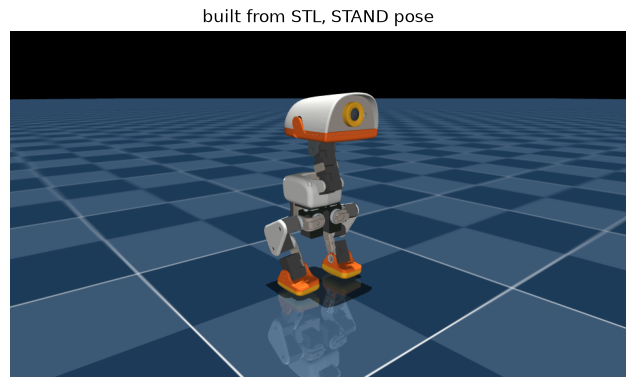

In [8]:
def make_camera(lookat):
    camera = mujoco.MjvCamera()
    camera.lookat[:] = lookat
    camera.distance, camera.azimuth, camera.elevation = 0.6, 140, -15
    return camera


with mujoco.Renderer(model, HEIGHT, WIDTH) as renderer:
    renderer.update_scene(data, make_camera(data.qpos[:3]))
    image = renderer.render()
plt.figure(figsize=(8, 4.5)); plt.imshow(image); plt.axis("off"); plt.title("built from STL, STAND pose");

## 4. Check against the reference MJCF

The build must be the model of `walk.ipynb`: same tree, masses, inertias, joint axes and limits, mesh placement and
contact flags, and the same sites in the STAND pose. The servo dofs must carry the BAM values that `walk.ipynb` sets
after loading; the reference itself has the training-time values there.

In [9]:
reference = mujoco.MjModel.from_xml_path(REFERENCE)
reference_data = mujoco.MjData(reference)
mujoco.mj_resetDataKeyframe(reference, reference_data, reference.key("STAND").id)
mujoco.mj_forward(reference, reference_data)

for count in ("nbody", "njnt", "nq", "nv", "ngeom", "nsite", "nmesh"):
    assert getattr(model, count) == getattr(reference, count), f"{count}: {getattr(model, count)} vs {getattr(reference, count)}"
for kind, n in ((mujoco.mjtObj.mjOBJ_BODY, model.nbody), (mujoco.mjtObj.mjOBJ_JOINT, model.njnt),
                (mujoco.mjtObj.mjOBJ_SITE, model.nsite)):
    names = [mujoco.mj_id2name(m, kind, i) for m in (model, reference) for i in range(n)]
    assert names[:n] == names[n:], f"{kind} names differ"

servo = addresses(model, JOINTS)[1]
other = np.setdiff1d(np.arange(model.nv), servo)
fields = {
    "body_pos": (model.body_pos, reference.body_pos),
    "body_quat": (model.body_quat, reference.body_quat),
    "body_mass": (model.body_mass, reference.body_mass),
    "body_ipos": (model.body_ipos, reference.body_ipos),
    "body_iquat": (model.body_iquat, reference.body_iquat),
    "body_inertia": (model.body_inertia, reference.body_inertia),
    "jnt_axis": (model.jnt_axis, reference.jnt_axis),
    "jnt_range": (model.jnt_range, reference.jnt_range),
    "jnt_solref": (model.jnt_solref, reference.jnt_solref),
    "jnt_solimp": (model.jnt_solimp, reference.jnt_solimp),
    "geom_pos": (model.geom_pos, reference.geom_pos),
    "geom_quat": (model.geom_quat, reference.geom_quat),
    "geom_size": (model.geom_size, reference.geom_size),
    "geom_aabb": (model.geom_aabb, reference.geom_aabb),
    "geom_contype": (model.geom_contype, reference.geom_contype),
    "geom_conaffinity": (model.geom_conaffinity, reference.geom_conaffinity),
    "geom_friction": (model.geom_friction, reference.geom_friction),
    "dof_armature, not servo": (model.dof_armature[other], reference.dof_armature[other]),
    "dof_damping, not servo": (model.dof_damping[other], reference.dof_damping[other]),
    "dof_frictionloss, not servo": (model.dof_frictionloss[other], reference.dof_frictionloss[other]),
    "dof_armature, servo = BAM": (model.dof_armature[servo], ARMATURE),
    "dof_damping, servo = BAM": (model.dof_damping[servo], FRICTION_VISCOUS),
    "dof_frictionloss, servo = BAM": (model.dof_frictionloss[servo], FRICTION_BASE),
    "qpos STAND": (data.qpos, reference_data.qpos),
    "site_xpos STAND": (data.site_xpos, reference_data.site_xpos),
}
for name, (built, ref) in fields.items():
    error = np.max(np.abs(np.asarray(built, float) - np.asarray(ref, float)))
    print(f"{name:<30}{error:10.1e}")
    assert error < 1e-12, f"{name} differs from the reference by {error:.3e}"
print(f"total mass {model.body_subtreemass[0]:.6f} kg vs reference {reference.body_subtreemass[0]:.6f} kg")

body_pos                         0.0e+00
body_quat                        0.0e+00
body_mass                        0.0e+00
body_ipos                        0.0e+00
body_iquat                       0.0e+00
body_inertia                     0.0e+00
jnt_axis                         0.0e+00
jnt_range                        0.0e+00
jnt_solref                       0.0e+00
jnt_solimp                       0.0e+00
geom_pos                         0.0e+00
geom_quat                        0.0e+00
geom_size                        0.0e+00
geom_aabb                        0.0e+00
geom_contype                     0.0e+00
geom_conaffinity                 0.0e+00
geom_friction                    0.0e+00
dof_armature, not servo          0.0e+00
dof_damping, not servo           0.0e+00
dof_frictionloss, not servo      0.0e+00
dof_armature, servo = BAM        0.0e+00
dof_damping, servo = BAM         0.0e+00
dof_frictionloss, servo = BAM    0.0e+00
qpos STAND                       0.0e+00
site_xpos STAND 

## 5. Servo and standing

BAM xl330 voltage model on every joint. The position loop reads the encoder through the backlash, the firmware gain
turns the error into a duty cycle on the supply voltage, and the motor torque follows from back-EMF and winding
resistance. Standing: the robot starts in the STAND pose above the floor and the servos hold it, with the gain and
pass criteria of `MicroDuck.Examples.Standing`.

In [10]:
# bam/params/xl330/m6.json
KT = 0.3459739511711113
RESISTANCE = 2.501880848390462
# bam/dynamixel/actuator.py
SUPPLY = 7.4
ERROR_GAIN = (4096 / (2 * np.pi)) / (256 * 885)
GAIN = 200.0


def encoder(model, data):
    """Joint angles and speeds seen by the servo encoder, through the backlash."""
    qadr, dadr = addresses(model, JOINTS)
    bq, bd = addresses(model, BACKLASH_JOINTS)
    q, dq = data.qpos[qadr].copy(), data.qvel[dadr].copy()
    q += data.qpos[bq]
    dq += data.qvel[bd]
    return q, dq


def servo_force(model, data, target, gain=GAIN):
    """Apply the servo torque to the motor-side joints."""
    q, _ = encoder(model, data)
    dadr = addresses(model, JOINTS)[1]
    duty = np.clip((target - q) * gain * ERROR_GAIN, -1.0, 1.0)
    dq = data.qvel[dadr]
    data.qfrc_applied[dadr] = KT * SUPPLY * duty / RESISTANCE - KT ** 2 * dq / RESISTANCE


def pitch_of(data):
    w, x, y, z = data.qpos[3:7]
    return float(np.arcsin(np.clip(2 * (w * y - z * x), -1, 1)))

lowest sole 2.82 mm above the floor
after 2.0 s: trunk z 116.15 mm, pitch 2.38 deg, largest joint speed 1.7e-03 rad/s


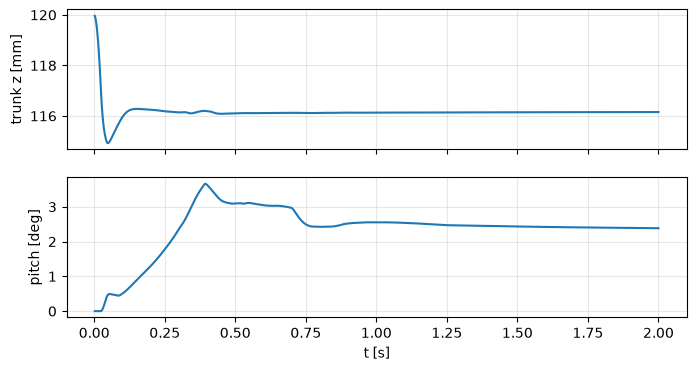

In [11]:
STAND_TIME = 2.0
STAND_GAIN = 800.0  # positionGain of MicroDuck.Examples.Standing; at the policy's 200 the robot falls without balancing
MIN_HEIGHT, REST_SPEED = 0.105, 1e-2  # pass criteria of MicroDuck.Examples.Standing

data = mujoco.MjData(model)
reset_stand(model, data)
home = np.array(list(STAND.values()))
floor = model.geom("floor").id
gap = min(mujoco.mj_geomDistance(model, data, model.geom(f"{side}_foot_collision").id, floor, 0.05, None)
          for side in ("left", "right"))
print(f"lowest sole {1000 * gap:.2f} mm above the floor")

t, z, pitch = [], [], []
while data.time < STAND_TIME:
    servo_force(model, data, home, STAND_GAIN)
    mujoco.mj_step(model, data)
    t.append(data.time); z.append(data.qpos[2]); pitch.append(pitch_of(data))
fig, ax = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
ax[0].plot(t, 1000 * np.array(z)); ax[0].set_ylabel("trunk z [mm]")
ax[1].plot(t, np.degrees(pitch)); ax[1].set_ylabel("pitch [deg]"); ax[1].set_xlabel("t [s]")
for a in ax:
    a.grid(alpha=0.3)
joint_speed = np.max(np.abs(encoder(model, data)[1]))
print(f"after {STAND_TIME} s: trunk z {1000 * z[-1]:.2f} mm, pitch {np.degrees(pitch[-1]):.2f} deg, "
      f"largest joint speed {joint_speed:.1e} rad/s")
assert z[-1] > MIN_HEIGHT, "the robot has collapsed"
assert joint_speed < REST_SPEED, "the joints have not come to rest"

## 6. Walking policy

Robot-software loop: 50 Hz control period, 61 observations (gyro, gravity, joint offsets, joint speeds, previous
action, command), 14 targets = home + 0.9 x action, first-order low-pass of 0.7 on the legs and 0.5 on the head.
As in training, targets reach the servos 22.5 ms late and joint speeds are observed one control period late.

In [12]:
PERIOD = 0.02
ACTION_SCALE = 0.9
LEGS_FILTER, HEAD_FILTER = 0.7, 0.5
COMMAND_DELAY = 0.0225  # s, mean of the 3 to 6 steps of 5 ms that training samples every step


def run(model, speed, duration, on_tick=None):
    data = mujoco.MjData(model)
    reset_stand(model, data)
    home = np.array(list(STAND.values()))
    delay_steps = round(COMMAND_DELAY / model.opt.timestep)
    commands = [home.copy()] * (delay_steps + 1)
    observed_speed = np.zeros(14)
    session = ort.InferenceSession(ONNX)
    imu = model.site("imu").id
    command = np.zeros(13)
    command[0] = speed
    last_action = np.zeros(14)
    previous = None
    substeps = round(PERIOD / model.opt.timestep)
    rows = []
    for _ in range(int(duration / PERIOD)):
        mujoco.mj_forward(model, data)
        rot = data.site_xmat[imu].reshape(3, 3)
        omega = np.zeros(6)
        mujoco.mj_objectVelocity(model, data, mujoco.mjtObj.mjOBJ_SITE, imu, omega, 1)  # local frame
        q, dq = encoder(model, data)
        obs = np.concatenate([omega[:3], rot.T @ np.array([0, 0, -1.0]), q - home,
                              observed_speed, last_action, command]).astype(np.float32)
        observed_speed = dq
        last_action = session.run(None, {"obs": obs[None]})[0][0].astype(float)
        target = home + ACTION_SCALE * last_action
        if previous is not None:
            for j in range(14):
                alpha = HEAD_FILTER if j in HEAD else LEGS_FILTER
                target[j] = alpha * target[j] + (1 - alpha) * previous[j]
        previous = target.copy()
        for _ in range(substeps):
            commands = commands[1:] + [target]
            servo_force(model, data, commands[0])
            mujoco.mj_step(model, data)
        if on_tick:
            on_tick(data)
        rows.append({"t": float(data.time), "pos": data.qpos[:3].tolist(), "pitch": pitch_of(data)})
    return rows

In [13]:
SPEED, DURATION = 0.3, 6.0

renderer = mujoco.Renderer(model, HEIGHT, WIDTH)
camera = make_camera([0, 0, 0.1])
writer = imageio.get_writer(str(VIDEO), fps=round(1 / PERIOD), macro_block_size=1)


def grab(d):
    camera.lookat[:] = d.qpos[:3]
    renderer.update_scene(d, camera)
    writer.append_data(renderer.render())


series = run(model, SPEED, DURATION, on_tick=grab)
writer.close(); renderer.close()
print(f"{len(series)} frames, final x {series[-1]['pos'][0]:.3f} m")

300 frames, final x 0.799 m


In [14]:
Video(str(VIDEO), embed=True, width=720)

mean speed over last 4 s: 0.132 m/s (command 0.3)


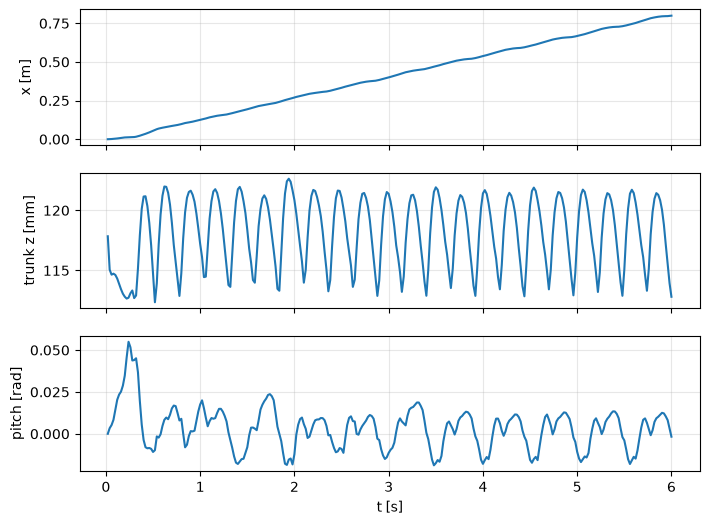

In [15]:
t = np.array([r["t"] for r in series])
x = np.array([r["pos"][0] for r in series])
z = np.array([r["pos"][2] for r in series])
pitch = np.array([r["pitch"] for r in series])
fig, ax = plt.subplots(3, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t, x); ax[0].set_ylabel("x [m]")
ax[1].plot(t, 1000 * z); ax[1].set_ylabel("trunk z [mm]")
ax[2].plot(t, pitch); ax[2].set_ylabel("pitch [rad]"); ax[2].set_xlabel("t [s]")
for a in ax:
    a.grid(alpha=0.3)
tail = t > t[-1] - 4
print(f"mean speed over last 4 s: {(x[-1] - x[tail][0]) / 4:.3f} m/s (command {SPEED})")

The same walk on the reference MJCF, set up as in `walk.ipynb` (XML actuators off, BAM values on the servo dofs).
Changing the armature after compiling leaves the constraint weights MuJoCo derives from it (`dof_invweight0`) at the
training value; `mj_setConst` recomputes them, as compiling the built model does. Identical models give
identical trajectories.

In [16]:
reference = mujoco.MjModel.from_xml_path(REFERENCE)
reference.opt.disableflags |= mujoco.mjtDisableBit.mjDSBL_ACTUATION
servo = addresses(reference, JOINTS)[1]
reference.dof_armature[servo] = ARMATURE
reference.dof_damping[servo] = FRICTION_VISCOUS
reference.dof_frictionloss[servo] = FRICTION_BASE
mujoco.mj_setConst(reference, mujoco.MjData(reference))  # constraint weights from the new armature, as compiled here
reference_series = run(reference, SPEED, DURATION)
error = max(np.max(np.abs(np.subtract(a["pos"], b["pos"]))) for a, b in zip(series, reference_series))
print(f"largest trunk position difference to the reference walk: {error:.1e} m")
assert error < 1e-9, "the built model walks differently from the reference"

largest trunk position difference to the reference walk: 0.0e+00 m
